# Histogram Practical (ABA Unit 1, Practical 5)

**Aim:** create histograms to analyse the distributions of business variables (Sahyadri Mart daily sales, synthetic).

Run the cells in order (Runtime → Run all). Nothing to install. The note `histogram-practical` on Sutra explains every step.

In [1]:
# Step 1. Load the data, pick S05 (the Pune Express store) and set a clean chart style
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
s05 = df[df["store_id"] == "S05"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
BLUE = "#257de0"   # one colour for one variable
print("Days for S05:", len(s05), "| footfall from", s05["footfall"].min(), "to", s05["footfall"].max())

Days for S05: 731 | footfall from 721 to 2486


In [2]:
# Step 2. A frequency table first: count S05's days in footfall classes of width 200
edges = list(range(700, 2501, 200))            # 700, 900, ..., 2500
classes = pd.cut(s05["footfall"], bins=edges, right=False)   # [700, 900) means 700 to 899
table = classes.value_counts(sort=False).rename("days").to_frame()
table["percent"] = (table["days"] / len(s05) * 100).round(1)
print(table.to_string())
print("Total days:", table["days"].sum())

              days  percent
footfall                   
[700, 900)      23      3.1
[900, 1100)    191     26.1
[1100, 1300)   244     33.4
[1300, 1500)   159     21.8
[1500, 1700)    78     10.7
[1700, 1900)    26      3.6
[1900, 2100)     5      0.7
[2100, 2300)     4      0.5
[2300, 2500)     1      0.1
Total days: 731


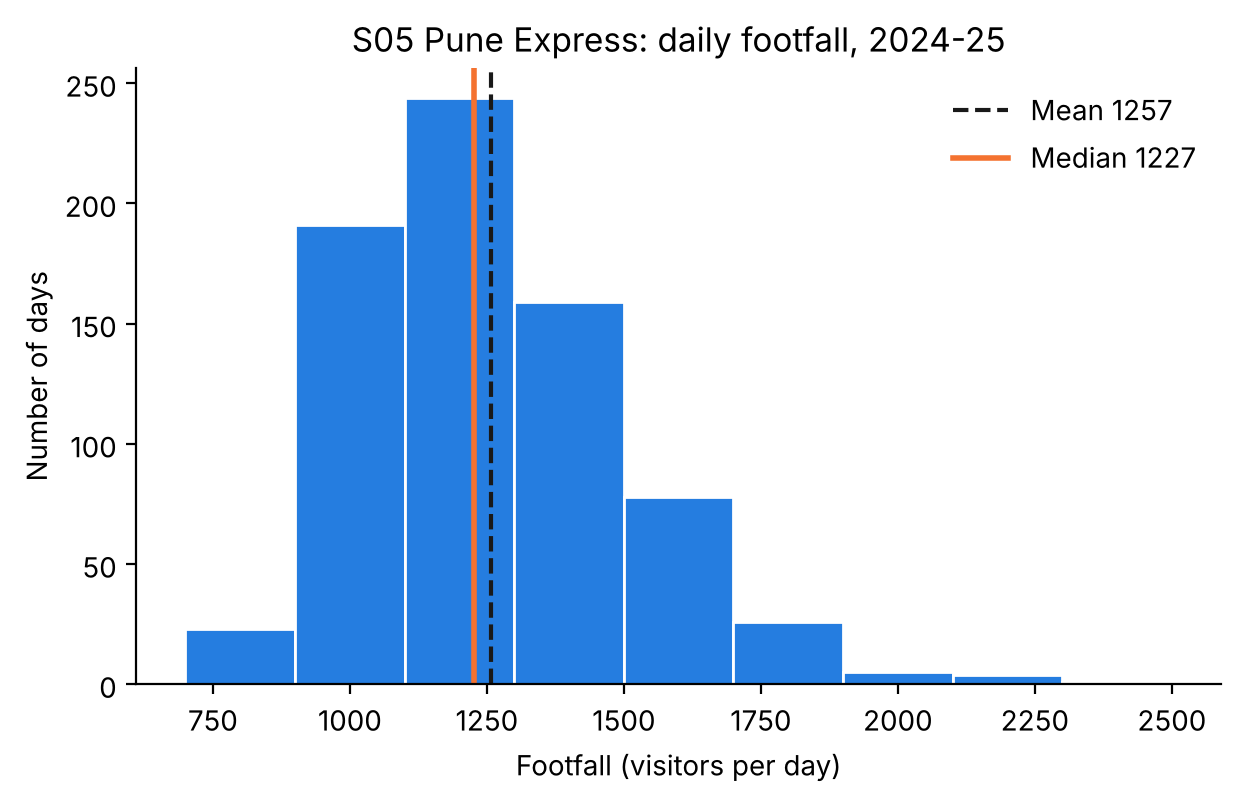

In [3]:
# Step 3. Draw the same table as a histogram, and mark the mean and median
f = s05["footfall"]
plt.figure(figsize=(7, 4))
plt.hist(f, bins=edges, color=BLUE, edgecolor="white")
plt.axvline(f.mean(), color="#191919", linestyle="--", linewidth=1.5, label=f"Mean {f.mean():.0f}")
plt.axvline(f.median(), color="#f47230", linewidth=2, label=f"Median {f.median():.0f}")
plt.title("S05 Pune Express: daily footfall, 2024-25")
plt.xlabel("Footfall (visitors per day)")
plt.ylabel("Number of days")
plt.legend(frameon=False)
plt.show()

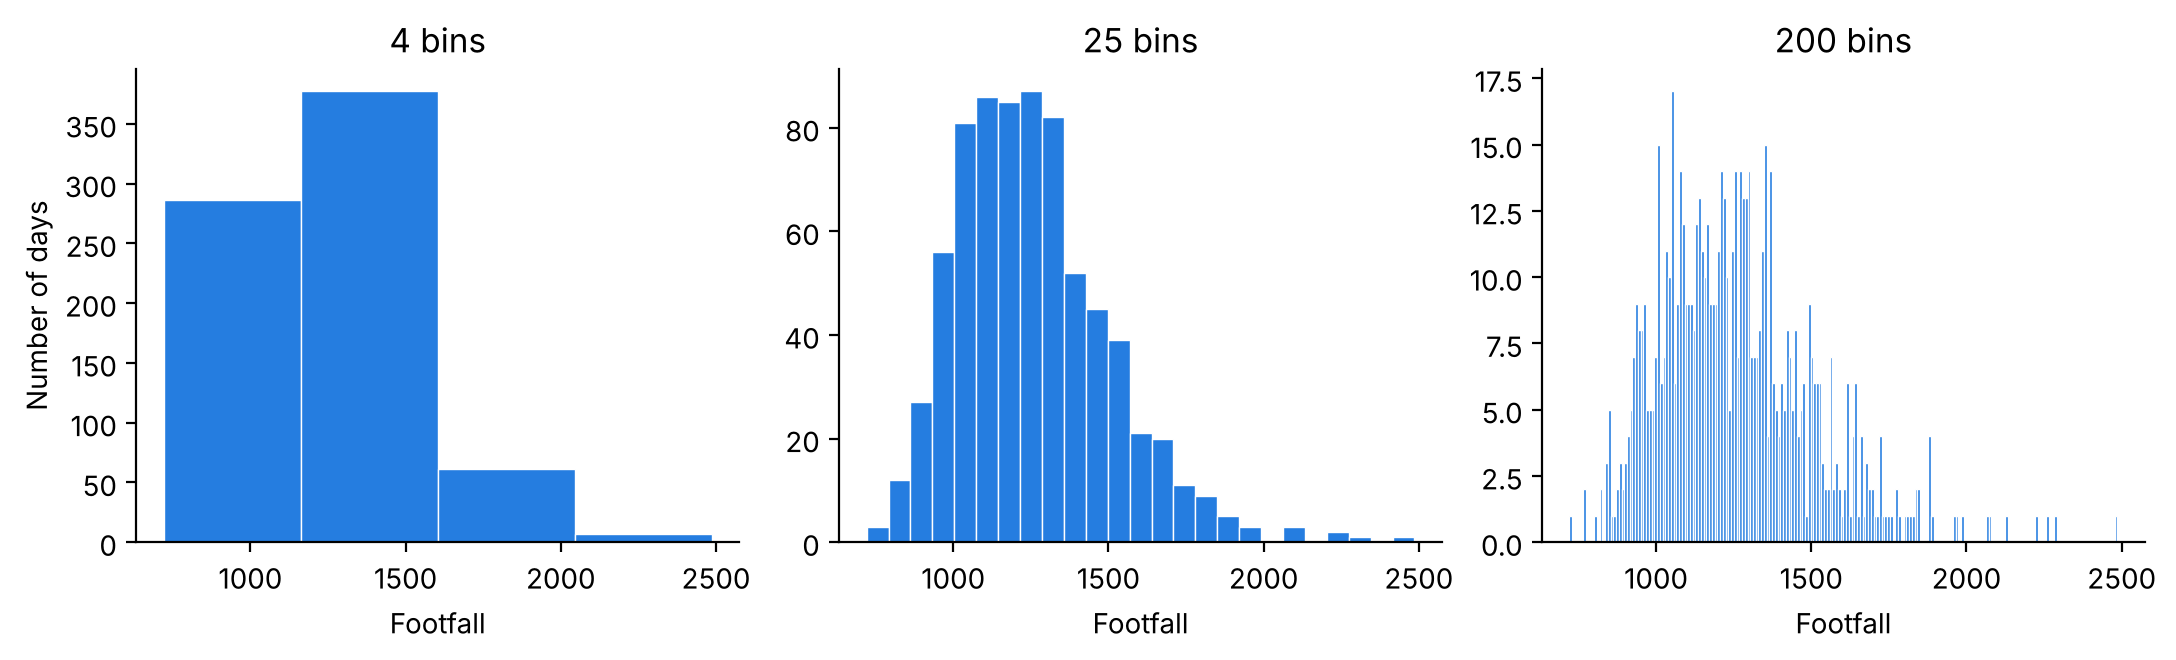

In [4]:
# Step 4. Same data, different bin counts: too few hide the shape, too many show noise
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=False)
for ax, b in zip(axes, [4, 25, 200]):
    ax.hist(f, bins=b, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{b} bins")
    ax.set_xlabel("Footfall")
axes[0].set_ylabel("Number of days")
plt.tight_layout()
plt.show()

S05 average bill (Rs)      mean    401.5  median    401.1  skewness -0.01
S05 footfall               mean   1257.3  median   1227.0  skewness  0.93
S01 Mumbai rainfall (mm)   mean      6.3  median      0.0  skewness  3.66


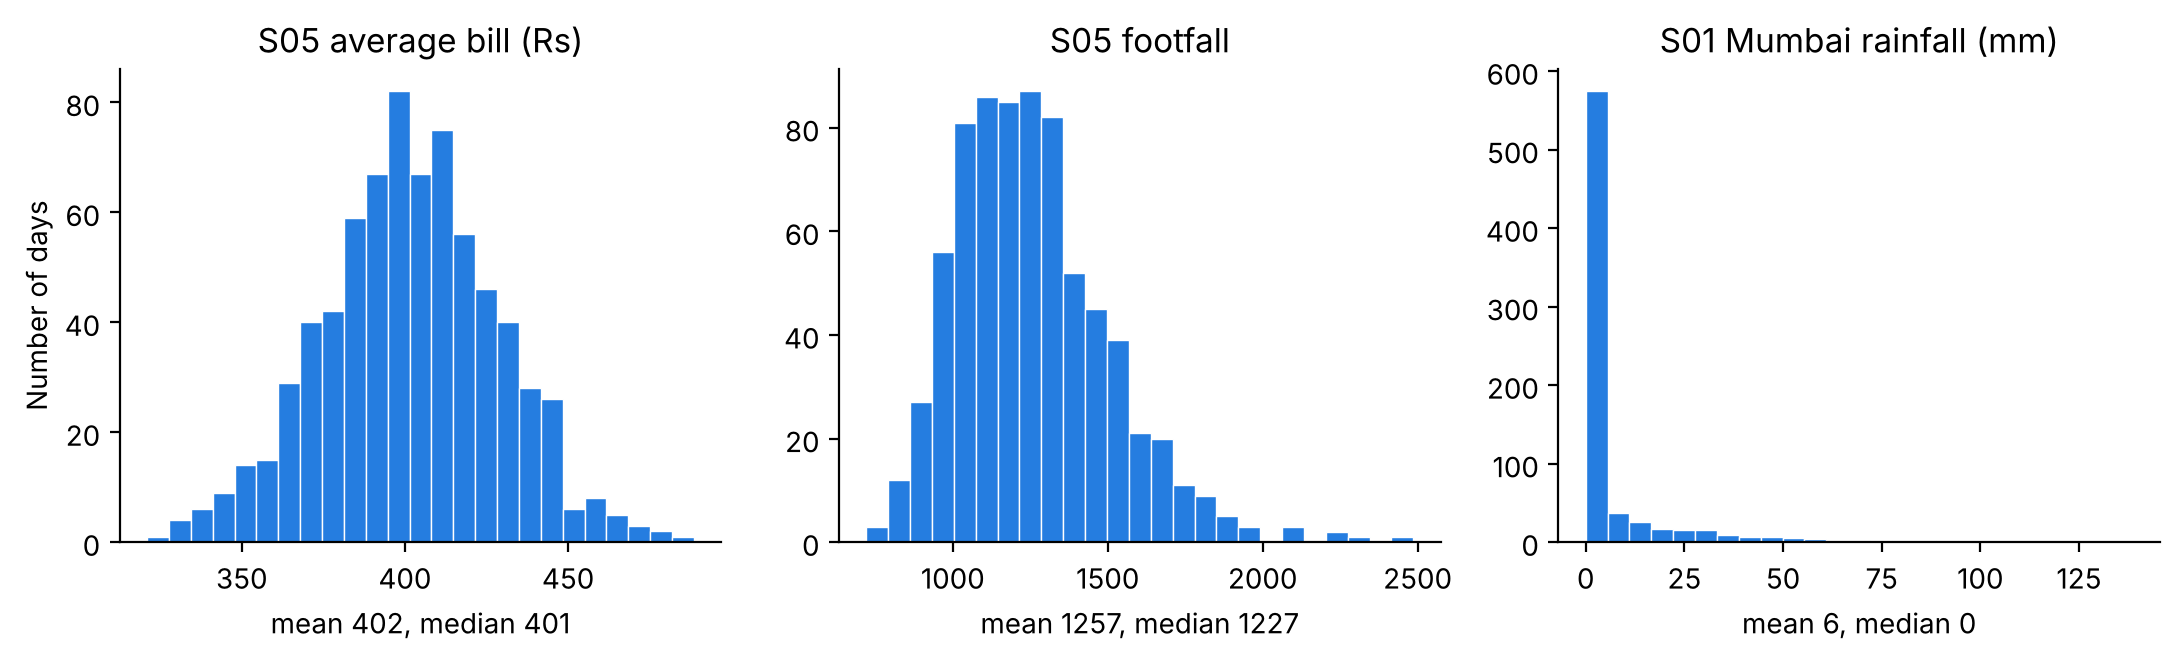

In [5]:
# Step 5. Three variables, three shapes: average bill, footfall and rainfall
s01 = df[df["store_id"] == "S01"]
cols = {
    "S05 average bill (Rs)": s05["revenue_inr"] / s05["transactions"],
    "S05 footfall": s05["footfall"],
    "S01 Mumbai rainfall (mm)": s01["rainfall_mm"],
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, x) in zip(axes, cols.items()):
    ax.hist(x.dropna(), bins=25, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel(f"mean {x.mean():.0f}, median {x.median():.0f}")
    print(f"{name:26s} mean {x.mean():8.1f}  median {x.median():8.1f}  skewness {x.skew():5.2f}")
axes[0].set_ylabel("Number of days")
plt.tight_layout()
plt.show()

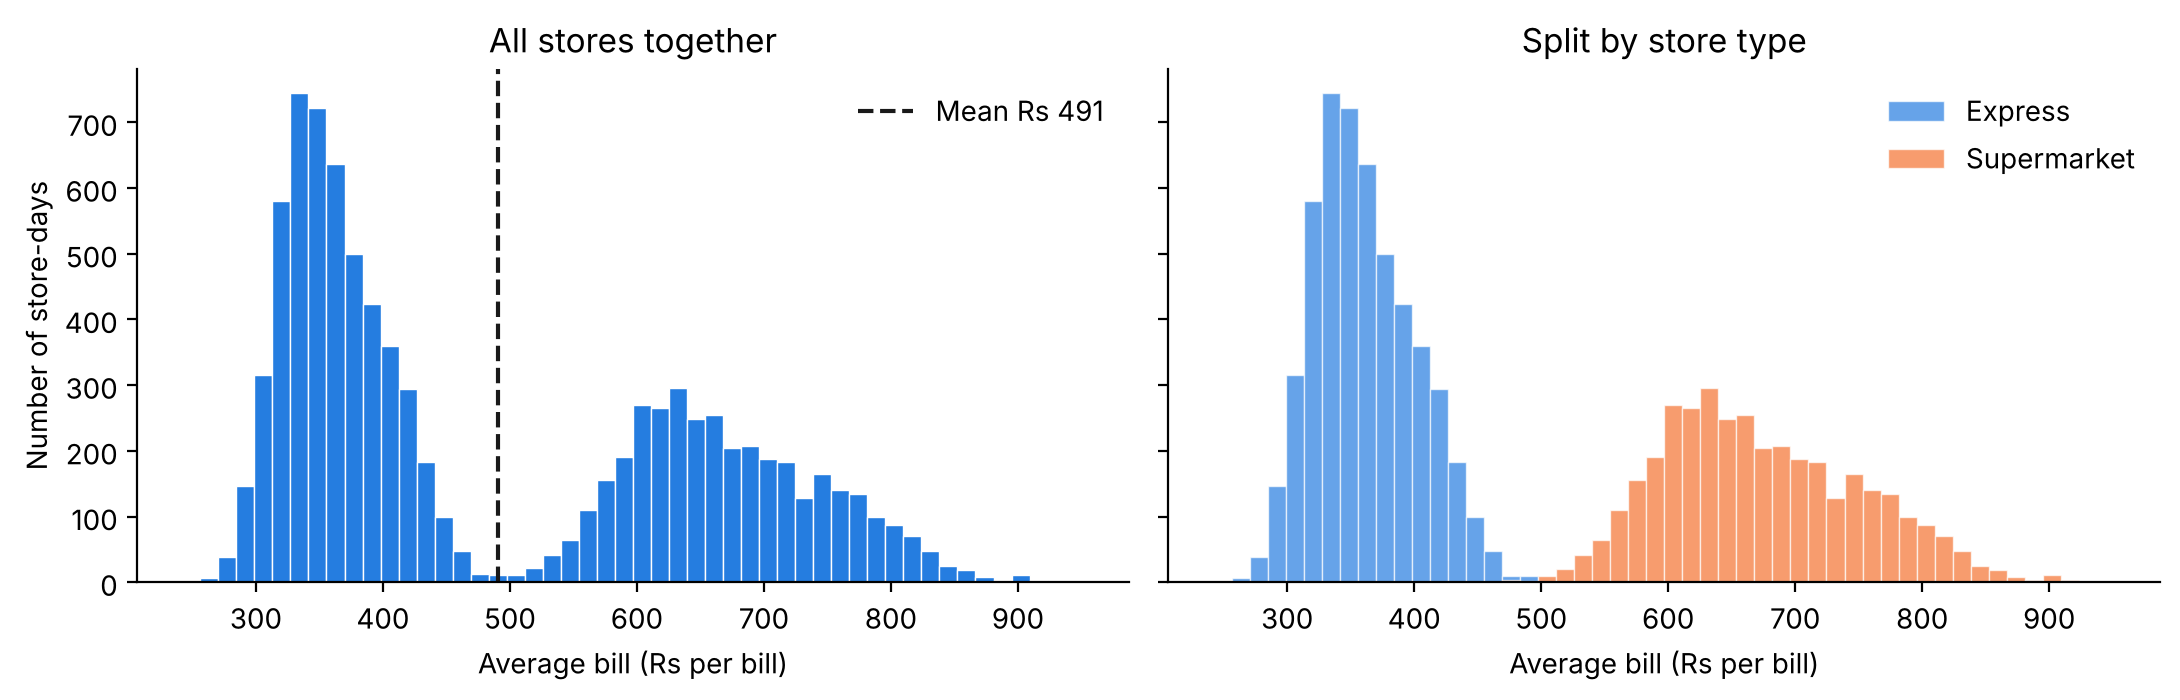

              mean  median
store_type                
Express      361.0   356.0
Supermarket  673.0   662.0
Store-days with an average bill between Rs 450 and Rs 530: 1.6%


In [6]:
# Step 6. All 12 stores together: the average bill has two humps. Why?
df["avg_bill"] = df["revenue_inr"] / df["transactions"]      # rupees per bill
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True, sharey=True)
axes[0].hist(df["avg_bill"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].axvline(df["avg_bill"].mean(), color="#191919", linestyle="--", linewidth=1.5,
                label=f"Mean Rs {df['avg_bill'].mean():.0f}")
axes[0].set_title("All stores together")
axes[0].legend(frameon=False)
for kind, colour in [("Express", BLUE), ("Supermarket", "#f47230")]:
    part = df.loc[df["store_type"] == kind, "avg_bill"]
    axes[1].hist(part, bins=50, range=(df["avg_bill"].min(), df["avg_bill"].max()),
                 color=colour, alpha=0.7, edgecolor="white", linewidth=0.5, label=kind)
axes[1].set_title("Split by store type")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xlabel("Average bill (Rs per bill)")
axes[0].set_ylabel("Number of store-days")
plt.tight_layout()
plt.show()
print(df.groupby("store_type")["avg_bill"].agg(["mean", "median"]).round(0).to_string())
between = df["avg_bill"].between(450, 530).mean() * 100
print(f"Store-days with an average bill between Rs 450 and Rs 530: {between:.1f}%")